# Séance 4 - Bonus : Réseau récurrent avec Embedding

Dans cette séance nous avons entraîné un modèle à copier le style de poésie de Beaudelaire, spécifiquement l'oeuvre *Les fleurs du mal*. On souhaite voir ici comment utiliser la couche [`Embedding`](https://keras.io/api/layers/core_layers/embedding/) et ce que l'on peut faire avec.

Commençons par importer les données.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style="whitegrid")

import tensorflow as tf
from tensorflow import keras

start = False
book = open("text\\Beaudelaire.txt", 'r' , encoding = 'utf8')
lines = book.readlines()
verses = []

for line in lines:
    line = line.strip().lower()
    if("Echoes".lower() in line and start==False):
        start = True
    if("End of Project Gutenberg's The Flowers of Evil, by Charles Baudelaire".lower() in line):
        break
    if(start==False or len(line) == 0):
        continue
    verses.append(line)

book.close()
text = " ".join(verses)
characters = sorted(set([character for character in text]))
n_characters = len(characters)

Dans le TP principal nous avons one-hot encodé le texte. La couche [`Embedding`](https://keras.io/api/layers/core_layers/embedding/) prend en entrée une séquence d'entier. Ainsi, nous devons changer la manière de construire $X$ et $y$.

**Consigne** : En s'inspirant du travail précédent, construire la matrice d'informations $X$ et le vecteur réponse $y$. Puis on scindera le dataset en un dataset d'entraînement et de validation.

In [3]:
sequence_length = 32
stride = 1
sequences = []
y_character = []
for index in range(0, len(text) - sequence_length, stride):
  sequences.append(text[index:index+sequence_length])
  y_character.append(text[index+sequence_length])

character_to_index = dict((character, index) for index, character in enumerate(characters))
index_to_character = dict((index, character) for index, character in enumerate(characters))

X = np.array(
    [[character_to_index[character] for character in sequence] for sequence in sequences],
    dtype=np.int32,
)
y = np.array([character_to_index[character] for character in y_character], dtype=np.int32)

split_index = int(0.8 * len(X))
validation_start = split_index + sequence_length
X_train, X_val = X[:split_index], X[validation_start:]
y_train, y_val = y[:split_index], y[validation_start:]


La couche [`Embedding`](https://keras.io/api/layers/core_layers/embedding/) a comme paramètre :
* *input_dim* : la taille du vocabulaire que l'on considère, ici *n_characters*
* *output_dim* : la dimension de l'embedding, autrement dit chaque caractère sera représenté comme un vecteur de *output_dim* dimension

On souhaite mesurer l'impact du paramètre *output_dim*. 

**Consigne** : Définir une fonction `get_model` qui prend en paramètre:
* *dimension* : un entier qui correspond à la dimension de sortie de l'embedding
* *vocabulary_size* : la taille du vocabulaire

La fonction renvoie un réseau de neurones récurrents avec une couche d'embedding paramétré en accord avec les paramètres de la fonction. On essayera de faire un modèle de taille raisonnable.


In [4]:
def get_model(dimension, vocabulary_size):
      model = keras.Sequential([
        keras.layers.Input(shape=(sequence_length,)),
        keras.layers.Embedding(vocabulary_size, dimension),
        keras.layers.LSTM(dimension, return_sequences=True),
        keras.layers.LSTM(dimension),
        keras.layers.Dense(vocabulary_size, activation="softmax"),
      ])
      model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"],
      )
      return model

**Consigne** : Écrire une boucle d'entraînement qui va stocker dans une liste le maximum atteint lors de l'entraînement jusqu'à 10 époques. Chaque élément de la liste correspondra à un dictionnaire avec pour clé:
* *dimension*: la dimension de l'embedding
* *val_loss*: la valeur de loss minimale atteinte sur le dataset de validation au cours de l'entraînement

In [5]:
n_epochs = 10
baches = 128

score = []
dimensions = []

for dimension in 32 * 2 ** np.arange(0, 4):
    callback = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
    model = get_model(int(dimension), vocabulary_size=n_characters)
    history = model.fit(
        X_train, 
        y_train, 
        epochs=n_epochs, 
        batch_size=baches, 
        validation_data=(X_val, y_val), 
        callbacks=callback, 
        verbose=0
        )
    
    score.append({
      "dimension": int(dimension),
      "loss": history.history["loss"][-1],
      "accuracy": history.history["accuracy"][-1],
      "val_loss": history.history["val_loss"][-1],
      "val_accuracy": history.history["val_accuracy"][-1],
    })

    dimensions.append(dimension)

In [6]:
h_df = pd.DataFrame(score)
display(h_df)

,dimension,loss,accuracy,val_loss,val_accuracy
0,32,2.247075,0.343358,2.243465,0.341789
1,64,2.081303,0.388093,2.079900,0.386182
2,128,1.818310,0.454558,1.884716,0.438474
3,256,1.202203,0.635079,1.892664,0.462394


**Consigne** : Modifier la structure de results pour correspondre à une liste de tuple où on a la moyenne et l'écart-type pour chaque entraînement pour une dimension précise.

In [7]:
n_repeats = 3
results = []

for dimension in dimensions:
    val_losses = []

    for _ in range(n_repeats):
        callback = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        )
        model = get_model(int(dimension), vocabulary_size=n_characters)
        history = model.fit(
            X_train,
            y_train,
            epochs=n_epochs,
            batch_size=baches,
            validation_data=(X_val, y_val),
            callbacks=[callback],
            verbose=0,
        )
        val_losses.append(min(history.history["val_loss"]))

    results.append((
        int(dimension),
        float(np.mean(val_losses)),
        float(np.std(val_losses)),
    ))

results

[(32, 2.2463866074879966, 0.014694423183857039),
 (64, 2.0724786122639975, 0.007531827415722743),
 (128, 1.8853387435277302, 0.02197328111551758),
 (256, 1.8014561732610066, 0.00567116436332387)]

**Consigne** : Visualiser puis commenter les résultats.

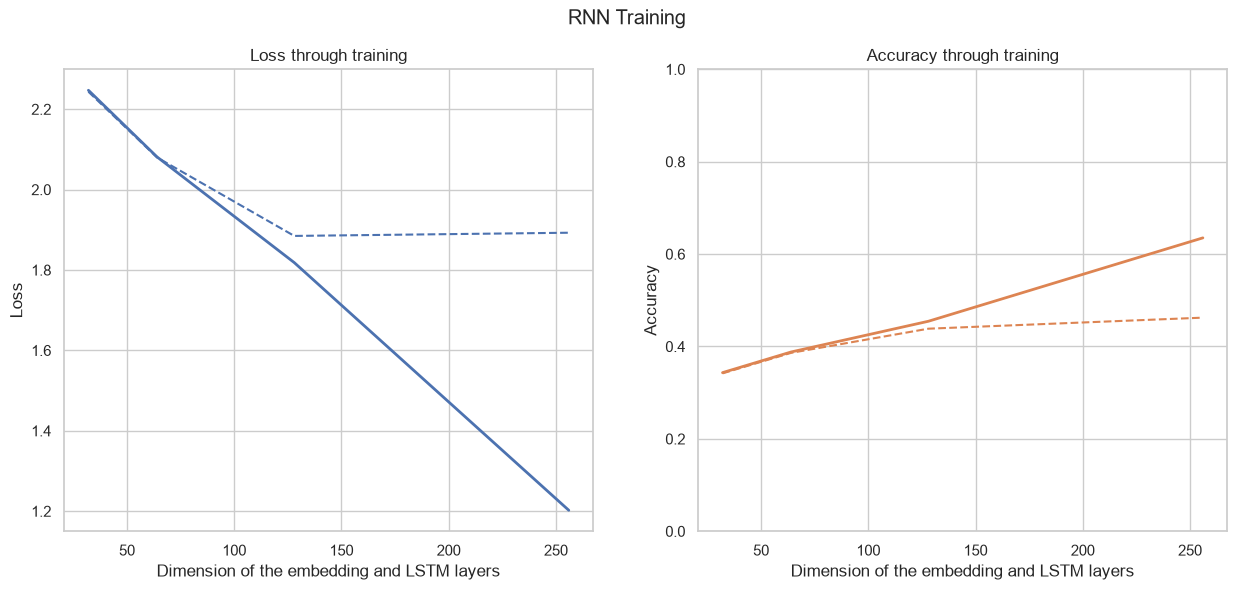

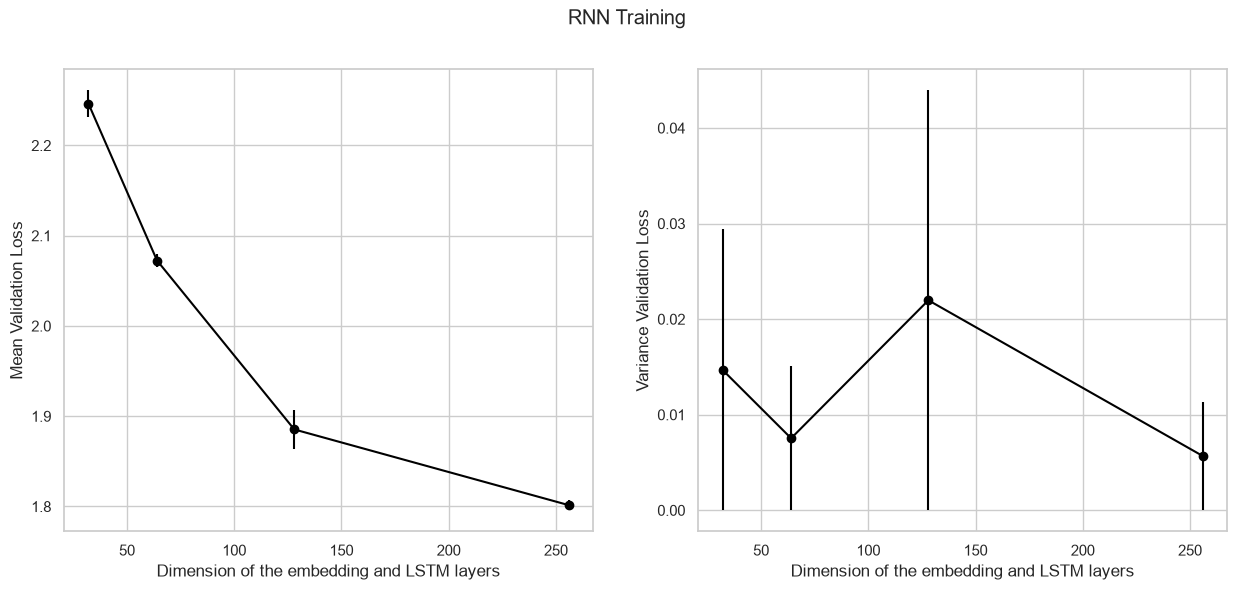

In [17]:
figure, (axis_1, axis_2) = plt.subplots(1, 2, figsize=(15, 6))

for index, (metric_name, axis) in enumerate(zip(["loss", "accuracy"], [axis_1, axis_2])):
  color = sns.color_palette()[index]
  axis.plot(dimensions, h_df[metric_name], lw=2, color=color)
  axis.plot(dimensions, h_df["val_" + metric_name], ls="--", color=color)

  if metric_name == "accuracy": axis.set_ylim(0, 1)
  axis.set_ylabel(metric_name.capitalize())
  axis.set_xlabel("Dimension of the embedding and LSTM layers")
  axis.set_title("%s through training" % metric_name.capitalize())


plt.suptitle("RNN Training")
plt.show()


figure, (axis_1, axis_2) = plt.subplots(1, 2, figsize=(15, 6))

dimensions = [row[0] for row in results]
mean_val_losses = [row[1] for row in results]
std_val_losses = [row[2] for row in results]

axis_1.plot(dimensions, mean_val_losses, color="black")
axis_1.errorbar(dimensions, mean_val_losses, yerr=std_val_losses, fmt="o", color="black")
axis_1.set_xlabel("Dimension of the embedding and LSTM layers")
axis_1.set_ylabel("Mean Validation Loss")

axis_2.plot(dimensions, std_val_losses, color="black")
axis_2.errorbar(dimensions, std_val_losses, yerr=std_val_losses, fmt="o", color="black")
axis_2.set_xlabel("Dimension of the embedding and LSTM layers")
axis_2.set_ylabel("Variance Validation Loss")

plt.suptitle("Validation Losses")

plt.suptitle("RNN Training")
plt.show()

On voit que plus on augmente la dimetion plus la validation diminue, l'accuratie augmente et la moyenne est reduite. Cependant il y a un plus grand ecart entre les score de validation et de train. 